# TP3 : normalisation, mots vides, racines et lemmes
**Traitement Automatique du Langage Naturel · EMSI · Chapitre 2 (partie 3) · Séance 8**

### Objectifs
1. utiliser et **adapter** une liste de mots vides (sans perdre la négation) ;
2. comparer la **racinisation** (Snowball, NLTK) et la **lemmatisation** (spaCy), en français et en anglais ;
3. **normaliser** un texte arabe (darija) ;
4. **mesurer** la taille du vocabulaire après chaque étape et **justifier** les choix.

### Mode d'emploi
- Complétez les cellules marquées `# À compléter` (remplacez les `...`).
- Exécutez ensuite la cellule **✅ Test** qui suit : elle doit afficher ✅.
- Répondez aux questions ✍️ dans la cellule « Votre réponse » placée juste en dessous.

### Livrable attendu
Le tableau comparatif commenté de la partie 4 et la fonction `normaliser_tp3()`.

## Partie 0 : préparation
### 0.1 Identification
Complétez vos informations puis exécutez la cellule : elle affiche le **nom du fichier** sous lequel
vous devez enregistrer et rendre votre notebook.

In [1]:
NOM = "Elhannak"
PRENOM = "Badr"
GROUPE = "G2"

assert NOM and PRENOM and GROUPE, "Complétez NOM, PRENOM et GROUPE"
nom_fichier = f"TP3_{NOM}_{PRENOM}_{GROUPE}.ipynb".replace(" ", "_")
print("Enregistrez votre notebook sous le nom :", nom_fichier)

Enregistrez votre notebook sous le nom : TP3_Elhannak_Badr_G2.ipynb


### 0.2 Installation et imports
Sur **Google Colab**, décommentez les 3 premières lignes la première fois (NLTK est déjà installé).
Sur votre machine : `pip install nltk spacy pandas matplotlib`, puis téléchargez les deux modèles spaCy.

In [11]:
# !pip install -q spacy
# !python -m spacy download fr_core_news_sm
# !python -m spacy download en_core_web_sm

import re, html, unicodedata
from collections import Counter

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer
from nltk.stem import PorterStemmer
from nltk.stem.isri import ISRIStemmer

import spacy
import pandas as pd
import matplotlib.pyplot as plt

nlp_fr = spacy.load("fr_core_news_sm")    # modèle français
nlp_en = spacy.load("en_core_web_sm")     # modèle anglais
print("NLTK", nltk.__version__, "| spaCy", spacy.__version__, "| pandas", pd.__version__)

NLTK 3.10.3 | spaCy 3.8.16 | pandas 3.0.6


### 0.3 Le corpus fil rouge
Trois petits corpus d'avis sur des restaurants, chacun avec son étiquette (`"pos"` ou `"neg"`) :
- `AVIS` : 26 avis **en français** ;
- `DARIJA` : 8 avis en **darija** écrits en lettres arabes, et 2 en **arabizi** ;
- `ENGLISH` : 6 avis **en anglais**.

In [12]:
AVIS = [
    ("Le tajine était délicieux et le service très rapide. Je recommande !", "pos"),
    ("Service TRÈS lent, le plat est arrivé froid. Je ne recommande pas.", "neg"),
    ("Les serveurs sont aimables et le cadre est magnifique 😍", "pos"),
    ("Le couscous n'était pas bon du tout, trop salé.", "neg"),
    ("Trooop bien !!! Livraison rapide et repas encore chaud.", "pos"),
    ("Livraison en retard de 45 minutes, la commande était incomplète.", "neg"),
    ("Très bon rapport qualité-prix, les portions sont généreuses.", "pos"),
    ("Le restaurant est sale et le personnel n'est pas aimable.", "neg"),
    ("J'ai adoré le thé à la menthe et les pâtisseries marocaines.", "pos"),
    ("Les prix sont trop élevés pour des plats sans goût.", "neg"),
    ("Accueil chaleureux, on s'est régalés en famille. Merci @dar_tajine !", "pos"),
    ("Plus jamais ! Le poisson n'était pas frais.", "neg"),
    ("Cadre agréable, musique douce, serveurs souriants.", "pos"),
    ("Commande annulée sans explication, service client injoignable.", "neg"),
    ("Le meilleur restaurant de Rabat, les brochettes sont excellentes.", "pos"),
    ("Les frites étaient froides et la sauce n'avait aucun goût.", "neg"),
    ("tres bon resto, je reviendrai avec mes amis", "pos"),
    ("Pas bon, pas chaud, pas rapide : rien ne va.", "neg"),
    ("Réservation facile sur https://dar-tajine.ma et accueil parfait.", "pos"),
    ("Le service était lent mais les plats étaient bons.", "pos"),
    ("Je ne suis pas satisfait, le livreur était impoli.", "neg"),
    ("Une expérience inoubliable, tout était parfait !", "pos"),
    ("Le restaurent est magnifque, les serveurs très gentils.", "pos"),
    ("Les plats sont arrivés froids, je ne commanderai plus jamais.", "neg"),
    ("Le plat est bon.", "pos"),
    ("Le plat n'est pas bon.", "neg"),
]

DARIJA = [
    ("الطاجين كان بنين بزاف و السيرفيس مزيان", "pos"),
    ("الماكلة باردة و الثمن غالي، ما عجبنيش", "neg"),
    ("المطعـــم زوين و الخدمة سريعة 👍", "pos"),
    ("ما غاديش نرجع ليه، الخدمة خايبة", "neg"),
    ("أحسن مطعم فالرباط، شُكْرًا بزااااف", "pos"),
    ("احسن طاجين كليتو، الأثمنة مناسبة", "pos"),
    ("التوصيل تعطل ساعة و الماكلة ما كانتش سخونة", "neg"),
    ("إلى بغيتي تاكل مزيان سير لهاد المطعم", "pos"),
    ("lmakla bnina bzaf, 3jbatni", "pos"),           # arabizi
    ("service 5ayb, ma 3jbnich", "neg"),             # arabizi
]

ENGLISH = [
    ("The waiters were friendly and the dishes tasted amazing.", "pos"),
    ("We waited two hours and the fries were cold.", "neg"),
    ("Best restaurant in Rabat, the tagines are delicious!", "pos"),
    ("The rooms were dirty and the staff wasn't helpful.", "neg"),
    ("The delivery arrived late and the boxes were broken.", "neg"),
    ("Lovely views, generously served meals and cheaper prices.", "pos"),
]
print(len(AVIS), "avis FR |", len(DARIJA), "avis darija |", len(ENGLISH), "avis EN")
print(Counter(etiquette for _, etiquette in AVIS))

26 avis FR | 10 avis darija | 6 avis EN
Counter({'pos': 14, 'neg': 12})


### 0.4 Le prétraitement du TP2 et l'analyse spaCy
La fonction `preprocess()` ci-dessous est une **version simplifiée** de celle du TP2 (vous pouvez la remplacer
par la vôtre). Elle remplace les liens par `<URL>`, les mentions par `<USER>` et réduit les allongements.

Pour que spaCy garde `<URL>` et `<USER>` en **un seul token**, on lui déclare deux **cas particuliers**.

In [13]:
def preprocess(texte):
    """Prétraitement du TP2 (version simplifiée)."""
    texte = html.unescape(texte)                       # &amp; -> &
    texte = re.sub(r"https?://\S+", " <URL> ", texte)  # liens
    texte = re.sub(r"@\w+", " <USER> ", texte)         # mentions
    texte = re.sub(r"(\w)\1{2,}", r"\1\1", texte)      # trooop -> troop
    return re.sub(r"\s+", " ", texte).strip()

for jeton in ["<URL>", "<USER>"]:                      # 1 token, pas 3
    nlp_fr.tokenizer.add_special_case(jeton, [{"ORTH": jeton}])

textes = [preprocess(t) for t, _ in AVIS]
docs = list(nlp_fr.pipe(textes))                       # analyse de tout le corpus
print(textes[18])
print([t.text for t in docs[18]])

Réservation facile sur <URL> et accueil parfait.
['Réservation', 'facile', 'sur', '<URL>', 'et', 'accueil', 'parfait', '.']


## Partie 1 : les mots vides
### Exercice 1.1 : comparer les listes de NLTK et de spaCy
Les deux bibliothèques fournissent une liste de mots vides français. Comparez-les avec les **opérations
sur les ensembles** : `&` (intersection), `-` (différence).

👉 La liste de spaCy se trouve dans `nlp_fr.Defaults.stop_words`.

In [15]:
sw_nltk = set(stopwords.words("french"))
sw_spacy = set(nlp_fr.Defaults.stop_words)          # À compléter : la liste de spaCy, convertie en set

communs = sw_nltk & sw_spacy            # À compléter : mots présents dans les DEUX listes
seulement_nltk = sw_nltk - sw_spacy     # À compléter : mots présents seulement dans NLTK
seulement_spacy = sw_spacy - sw_nltk    # À compléter : mots présents seulement dans spaCy

print("NLTK :", len(sw_nltk), "| spaCy :", len(sw_spacy), "| communs :", len(communs))
print("Seulement NLTK (15 premiers) :", sorted(seulement_nltk)[:15])
print("Seulement spaCy (15 premiers) :", sorted(seulement_spacy)[:15])

NLTK : 157 | spaCy : 507 | communs : 85
Seulement NLTK (15 premiers) : ['aient', 'aies', 'aurai', 'aurais', 'auras', 'aurez', 'auriez', 'aurions', 'aurons', 'avez', 'aviez', 'avions', 'ayante', 'ayantes', 'ayants']
Seulement spaCy (15 premiers) : ['a', 'abord', 'afin', 'ah', 'ainsi', 'allaient', 'allons', 'alors', 'anterieur', 'anterieure', 'anterieures', 'antérieur', 'antérieure', 'antérieures', 'apres']


In [ ]:
# ✅ Test 1.1 (ne pas modifier)
assert isinstance(sw_spacy, set) and "le" in sw_spacy, "sw_spacy doit être un set (utilisez set(...))"
assert communs == sw_nltk & sw_spacy, "communs : mots présents dans les deux listes (opérateur &)"
assert seulement_nltk == sw_nltk - sw_spacy, "seulement_nltk : opérateur -"
assert seulement_spacy == sw_spacy - sw_nltk, "seulement_spacy : opérateur -"
print("✅ Exercice 1.1 réussi")

Observez : NLTK contient `"l"`, `"n"`, `"qu"` **sans apostrophe**, alors que spaCy découpe `l'`, `n'`, `qu'`
**avec** l'apostrophe. Vérifions quels mots de la négation sont dans chaque liste :

In [16]:
for mot in ["ne", "n'", "n", "pas", "plus", "jamais", "rien", "aucun", "sans", "très", "trop", "mais"]:
    print(f"{mot:7} NLTK : {str(mot in sw_nltk):5}  spaCy : {mot in sw_spacy}")

ne      NLTK : True   spaCy : True
n'      NLTK : False  spaCy : True
n       NLTK : True   spaCy : False
pas     NLTK : True   spaCy : True
plus    NLTK : False  spaCy : True
jamais  NLTK : False  spaCy : False
rien    NLTK : False  spaCy : False
aucun   NLTK : False  spaCy : False
sans    NLTK : False  spaCy : True
très    NLTK : False  spaCy : True
trop    NLTK : False  spaCy : False
mais    NLTK : True   spaCy : True


?? **Question 1.1** : (a) Quelle liste est la plus longue ? (b) Pourquoi la liste de NLTK ne retire-t-elle pas
le token `n'` produit par spaCy ? (c) Quels mots de la n?gation sont dans les deux listes ?

> **Votre r?ponse :**
> (a) La liste spaCy est la plus longue (507 mots contre 157 pour NLTK). (b) NLTK contient `n` sans apostrophe, tandis que spaCy produit le token `n'` : les cha?nes ne sont pas identiques, donc l'appartenance ?choue. (c) Parmi les mots de n?gation test?s, `ne` et `pas` sont dans les deux listes. `n'` n'est que dans spaCy ; `plus` n'est que dans spaCy et `jamais`, `rien`, `aucun` ne sont dans aucune des deux.

### Exercice 1.2 : quelle part du corpus représentent les mots vides ?
1. Construisez la liste `mots` de tous les tokens **alphabétiques** du corpus, en minuscules
   (attributs spaCy `t.is_alpha` et `t.lower_`).
2. Comptez-les avec `Counter` et affichez les 10 plus fréquents.
3. Calculez la **proportion** de tokens qui sont des mots vides (liste spaCy).

In [17]:
mots = [t.lower_ for doc in docs for t in doc if t.is_alpha]   # tokens alphabétiques, en minuscules
freq = Counter(mots)                                           # Counter des mots
top10 = freq.most_common(10)                                   # les 10 mots les plus fréquents

nb_vides = sum(m in sw_spacy for m in mots)                    # tokens qui sont des mots vides (liste spaCy)
proportion = nb_vides / len(mots)                              # nb_vides / nombre total de tokens

print(len(mots), "tokens,", len(freq), "mots différents")
print(top10)
print(f"Mots vides : {nb_vides} tokens, soit {proportion:.0%} du corpus")

219 tokens, 119 mots différents
[('le', 15), ('pas', 9), ('les', 9), ('est', 8), ('était', 7), ('et', 7), ('bon', 6), ('je', 5), ('sont', 5), ('service', 4)]
Mots vides : 105 tokens, soit 48% du corpus


In [18]:
# ✅ Test 1.2
assert isinstance(mots, list) and all(m == m.lower() and m.isalpha() for m in mots), "mots : tokens alphabétiques en minuscules"
assert freq == Counter(mots), "freq doit être Counter(mots)"
assert len(top10) == 10 and top10[0] == freq.most_common(1)[0], "top10 : freq.most_common(10)"
assert abs(proportion - sum(m in sw_spacy for m in mots) / len(mots)) < 1e-9, "proportion incorrecte"
print("✅ Exercice 1.2 réussi")

✅ Exercice 1.2 réussi


### Exercice 1.3 : retirer les mots vides… et perdre la négation
Écrivez la fonction `retirer_mots_vides(tokens, mots_vides)` qui renvoie la liste des tokens qui ne sont
**ni** des mots vides **ni** de la ponctuation. `tokens` est une liste de tokens spaCy ; on renvoie leur
forme en minuscules (`t.lower_`).

In [19]:
def retirer_mots_vides(tokens, mots_vides):
    return [t.lower_ for t in tokens if not t.is_punct and t.lower_ not in mots_vides]

for phrase in ["Le plat est bon.", "Le plat n'est pas bon.", "Le plat n'est jamais bon."]:
    doc = nlp_fr(phrase)
    print(f"{phrase:28}", retirer_mots_vides(doc, sw_spacy))

Le plat est bon.             ['plat', 'bon']
Le plat n'est pas bon.       ['plat', 'bon']
Le plat n'est jamais bon.    ['plat', 'jamais', 'bon']


In [20]:
# ✅ Test 1.3
assert retirer_mots_vides(nlp_fr("Le service est rapide !"), sw_spacy) == ["service", "rapide"], "retirez les mots vides ET la ponctuation, en minuscules"
assert retirer_mots_vides(nlp_fr("Le plat n'est pas bon."), set()) == ["le", "plat", "n'", "est", "pas", "bon"], "avec une liste vide, seule la ponctuation doit partir"
print("✅ Exercice 1.3 réussi")

✅ Exercice 1.3 réussi


?? **Question 1.3** : Comparez les deux premi?res lignes. Quel est le probl?me pour l'**analyse de sentiment** ?
Pourquoi ? jamais ? est-il conserv? ?

> **Votre r?ponse :**
> ? Le plat est bon ? et ? Le plat n'est pas bon ? deviennent tous deux `['plat', 'bon']` : retirer `n'` et `pas` efface la n?gation et peut inverser le sentiment pr?dit. ? Jamais ? reste car il n'appartient pas ? la liste de mots vides spaCy utilis?e ici.

### Exercice 1.4 : construire une liste adaptée au corpus
On part de la liste de spaCy et :
1. on **retire** de la liste les mots de la négation (`NEGATION`) et d'intensité (`INTENSITE`), qu'on veut **garder** ;
2. on **ajoute** des mots du domaine, très fréquents dans tous les avis et donc peu utiles pour les distinguer.

Pour choisir les mots du domaine, la cellule suivante calcule la **fréquence documentaire** : le nombre
d'avis dans lesquels chaque mot (non vide) apparaît.

In [21]:
df = Counter()
for doc in docs:
    df.update({t.lower_ for t in doc if t.is_alpha and t.lower_ not in sw_spacy})
print(df.most_common(10))

[('bon', 6), ('service', 4), ('rapide', 3), ('plat', 3), ('serveurs', 3), ('plats', 3), ('recommande', 2), ('lent', 2), ('cadre', 2), ('trop', 2)]


In [22]:
NEGATION = {"ne", "n'", "pas", "plus", "jamais", "rien", "aucun", "aucune", "sans", "ni"}
INTENSITE = {"très", "trop", "peu"}
MOTS_DOMAINE = {"restaurant", "plat", "plats"}    # mots du domaine, très fréquents dans tous les avis

mots_vides_tp = (set(sw_spacy) - NEGATION - INTENSITE) | MOTS_DOMAINE

print(len(mots_vides_tp), "mots vides dans la liste adaptée")
for phrase in ["Le plat est bon.", "Le plat n'est pas bon.", "Le restaurant est très sale."]:
    print(f"{phrase:30}", retirer_mots_vides(nlp_fr(phrase), mots_vides_tp))

502 mots vides dans la liste adaptée
Le plat est bon.               ['bon']
Le plat n'est pas bon.         ["n'", 'pas', 'bon']
Le restaurant est très sale.   ['très', 'sale']


In [23]:
# ✅ Test 1.4
assert isinstance(mots_vides_tp, set), "mots_vides_tp doit être un set"
assert "le" in mots_vides_tp and "est" in mots_vides_tp, "les mots vides habituels doivent rester"
assert not ({"pas", "ne", "n'", "jamais", "très"} & mots_vides_tp), "la négation et l'intensité doivent être GARDÉES"
assert MOTS_DOMAINE and MOTS_DOMAINE <= mots_vides_tp, "ajoutez vos mots du domaine"
assert retirer_mots_vides(nlp_fr("Le plat est bon."), mots_vides_tp) != retirer_mots_vides(nlp_fr("Le plat n'est pas bon."), mots_vides_tp)
print("✅ Exercice 1.4 réussi : la négation est conservée")

✅ Exercice 1.4 réussi : la négation est conservée


?? **Question 1.4** : Quels mots du domaine avez-vous ajout?s ? Justifiez avec `df`.
Pourquoi ne faut-il pas ajouter ? service ? ou ? bon ? ?

> **Votre r?ponse :**
> J'ai ajout? `restaurant`, `plat` et `plats` : ils sont fr?quents dans le corpus (notamment `plat` et `plats` figurent parmi les premiers de `df`) et d?crivent le domaine plut?t que l'opinion. Il ne faut pas retirer `service` ni `bon` : `service` d?crit un aspect ?valu? et `bon` porte directement une polarit? positive ; les supprimer ferait perdre une information utile au sentiment.

## Partie 2 : racines (Snowball) et lemmes (spaCy)
### 2.1 À la main d'abord
Avant d'exécuter le code, **prédisez** la racine que Snowball va donner pour chaque mot, puis vérifiez avec
l'exercice 2.1. Rappel : Snowball **coupe les suffixes** (‑ons, ‑ait, ‑ement, ‑eur…) sans dictionnaire.

| Mot | Votre prédiction | Snowball |
|---|---|---|
| mangeons | mang | mangeon |
| rapidement | rapid | rapid |
| livraison | livr | livraison |
| livreur | livr | livreur |
| serveuse | serv | serveux |

### Exercice 2.1 : la racinisation avec Snowball
Complétez la fonction `raciner(mots)` qui renvoie la liste des racines, puis la fonction `nb_racines(mots)` qui
renvoie le **nombre de racines différentes** d'une famille de mots.

In [24]:
stemmer_fr = SnowballStemmer("french")

def raciner(mots):
    return [stemmer_fr.stem(mot) for mot in mots]

def nb_racines(mots):
    return len(set(raciner(mots)))

familles = {
    "manger":  ["mange", "mangeons", "mangeait", "mang?", "mangeur"],
    "rapide":  ["rapide", "rapides", "rapidement", "rapidit?"],
    "livrer":  ["livrer", "livraison", "livreur", "livr?"],
    "servir":  ["servir", "service", "serveur", "serveuse", "servi"],
    "aller":   ["aller", "allons", "va", "irai"],
}
for nom, mots_famille in familles.items():
    print(f"{nom:8} {nb_racines(mots_famille)} racine(s) :", raciner(mots_famille))

manger   4 racine(s) : ['mang', 'mangeon', 'mang', 'mang?', 'mangeur']
rapide   2 racine(s) : ['rapid', 'rapid', 'rapid', 'rapidit?']
livrer   4 racine(s) : ['livr', 'livraison', 'livreur', 'livr?']
servir   4 racine(s) : ['serv', 'servic', 'serveur', 'serveux', 'serv']
aller    4 racine(s) : ['aller', 'allon', 'va', 'irai']


In [25]:
# ✅ Test 2.1
assert raciner(["mangeait", "rapides"]) == ["mang", "rapid"], "raciner doit renvoyer la LISTE des racines"
assert nb_racines(["mange", "mangé", "mangeait"]) == 1 and nb_racines(["va", "irai"]) == 2, "nb_racines : len(set(...))"
print("✅ Exercice 2.1 réussi")

✅ Exercice 2.1 réussi


### Exercice 2.2 : la lemmatisation avec spaCy
Écrivez `lemmatiser(texte)` qui renvoie la liste des **lemmes en minuscules** des tokens d'un texte, sans la
ponctuation. Un lemme s'obtient avec `t.lemma_`.

In [26]:
def lemmatiser(texte):
    doc = nlp_fr(texte)
    return [t.lemma_.lower() for t in doc if not t.is_punct and not t.is_space]

print(lemmatiser("Les serveurs ?taient aimables et nous avons mang? des tajines d?licieux."))
print(lemmatiser("Nous irons, tu vas, ils allaient."))

['le', 'serveur', 'taient', 'aimable', 'et', 'nous', 'avoir', 'mang', 'un', 'tajine', 'd?licieux']
['nous', 'aller', 'tu', 'va', 'il', 'aller']


In [27]:
# ✅ Test 2.2
assert lemmatiser("Les serveurs étaient aimables.") == ["le", "serveur", "être", "aimable"], "lemmes en minuscules, sans la ponctuation"
print("✅ Exercice 2.2 réussi")

✅ Exercice 2.2 réussi


### Exercice 2.3 : tableau comparatif mot / racine / lemme
Pour chaque token (hors ponctuation) de l'avis ci-dessous, ajoutez une ligne
`{"mot": ..., "racine": ..., "lemme": ..., "catégorie": ...}` à la liste `lignes`, puis affichez le tableau
avec pandas. La catégorie s'obtient avec `t.pos_`.

In [51]:
avis = "Les serveurs étaient souriants mais les livraisons arrivaient froides."
lignes = []
for t in nlp_fr(avis):
    if not t.is_punct and not t.is_space:
        lignes.append({
            "mot": t.text,
            "racine": stemmer_fr.stem(t.lower_),
            "lemme": t.lemma_.lower(),
            "catégorie": t.pos_,
        })

tableau = pd.DataFrame(lignes)
tableau

,mot,racine,lemme,catégorie
0,Les,le,le,DET
1,serveurs,serveur,serveur,NOUN
2,étaient,étaient,être,AUX
3,souriants,souri,souriant,ADJ
4,mais,mais,mais,CCONJ
5,les,le,le,DET
6,livraisons,livraison,livraison,NOUN
7,arrivaient,arriv,arriver,VERB
8,froides,froid,froid,ADJ


In [50]:
# ✅ Test 2.3
assert list(tableau.columns) == ["mot", "racine", "lemme", "catégorie"], "4 colonnes : mot, racine, lemme, catégorie"
assert len(tableau) == 9 and tableau.loc[0, "lemme"] == "le", "une ligne par token (9 tokens hors ponctuation)"
print("✅ Exercice 2.3 réussi")

✅ Exercice 2.3 réussi


?? **Question 2.3** : Donnez un mot pour lequel la racine n'est **pas un vrai mot** et un mot o? le lemme
est **plus utile** que la racine. Quel est l'avantage de la racine ?

> **Votre r?ponse :**
> `souriant` donne la racine `souri` (qui n'est pas un mot fran?ais courant). Pour `?taient`, le lemme `?tre` est plus informatif et lisible que sa racine tronqu?e. La racinisation est simple et rapide ; elle regroupe des formes proches sans n?cessiter de mod?le linguistique.

### Exercice 2.4 : et en anglais ?
Comparez **Porter**, **Snowball (english)** et les lemmes de **spaCy (anglais)** sur les tokens alphabétiques des
avis `ENGLISH`. Construisez un tableau avec une ligne par mot **différent**.

In [32]:
porter = PorterStemmer()
snow_en = SnowballStemmer("english")

lignes_en = []
deja_vus = set()
for texte, _ in ENGLISH:
    for t in nlp_en(texte):
        mot = t.lower_
        if t.is_alpha and mot not in deja_vus:
            deja_vus.add(mot)
            lignes_en.append({
                "mot": mot,
                "Porter": porter.stem(mot),
                "Snowball": snow_en.stem(mot),
                "lemme spaCy": t.lemma_.lower(),
            })

tableau_en = pd.DataFrame(lignes_en)
tableau_en[(tableau_en["Porter"] != tableau_en["mot"]) | (tableau_en["lemme spaCy"] != tableau_en["mot"])]

,mot,Porter,Snowball,lemme spaCy
1,waiters,waiter,waiter,waiter
2,were,were,were,be
3,friendly,friendli,friend,friendly
5,dishes,dish,dish,dish
6,tasted,tast,tast,taste
7,amazing,amaz,amaz,amazing
9,waited,wait,wait,wait
11,hours,hour,hour,hour
12,fries,fri,fri,fry
14,best,best,best,good


In [33]:
# ✅ Test 2.4
assert list(tableau_en.columns) == ["mot", "Porter", "Snowball", "lemme spaCy"]
ligne = tableau_en[tableau_en["mot"] == "were"].iloc[0]
assert ligne["lemme spaCy"] == "be" and ligne["Porter"] == "were"
print("✅ Exercice 2.4 réussi")

✅ Exercice 2.4 réussi


?? **Question 2.4** : Rep?rez dans le tableau (a) un verbe irr?gulier que seul spaCy ram?ne ? sa forme de base,
(b) un mot que Porter coupe de fa?on illisible, (c) une diff?rence entre Porter et Snowball.

> **Votre r?ponse :**
> (a) `were` : spaCy le ram?ne ? `be`, contrairement ? Porter et Snowball qui le laissent tel quel. (b) `delicious` est coup? en `delici` par Porter, une forme peu lisible. (c) Les deux stemmers produisent parfois des radicaux diff?rents pour un m?me mot, par exemple `generously` : Porter donne `gener`, Snowball `generous`.

### Exercice 2.5 : repérer la sur-racinisation dans le corpus
Une racine peut regrouper des mots de **sens différents**. Pour le vérifier, on associe à chaque racine
l'ensemble des **lemmes** qui la produisent. Une racine avec plusieurs lemmes est **suspecte**.

In [34]:
racine_vers_lemmes = {}
for doc in docs:
    for t in doc:
        if t.is_alpha and t.lower_ not in mots_vides_tp:
            r = stemmer_fr.stem(t.lower_)
            racine_vers_lemmes.setdefault(r, set()).add(t.lemma_.lower())

suspects = {r: lemmes for r, lemmes in racine_vers_lemmes.items() if len(lemmes) >= 2}
for r, lemmes in sorted(suspects.items()):
    print(f"{r:10} <- {sorted(lemmes)}")

command    <- ['commande', 'commander']
froid      <- ['froid', 'froider']
sal        <- ['sale', 'salé']


In [35]:
# ✅ Test 2.5
assert all(len(l) >= 2 for l in suspects.values()) and len(suspects) >= 1
print("✅ Exercice 2.5 réussi :", len(suspects), "racine(s) suspecte(s)")

✅ Exercice 2.5 réussi : 3 racine(s) suspecte(s)


?? **Question 2.5** : Pour chaque racine affich?e, s'agit-il d'une **vraie** sur-racinisation (sens diff?rents) ou
d'une **erreur du lemmatiseur** (le petit mod?le spaCy se trompe) ? Que concluez-vous ?

> **Votre r?ponse :**
> Une racine associ?e ? des lemmes de sens distincts r?v?le une sur-racinisation ; si les lemmes sont des variantes du m?me mot mais qu'un lemme spaCy para?t incoh?rent dans le contexte, c'est plut?t une erreur du mod?le. Les racines affich?es doivent donc ?tre interpr?t?es avec le contexte et les mots du tableau, pas comme des lemmes. La racinisation r?duit davantage les formes mais peut fusionner ? tort ; la lemmatisation reste plus lisible, tout en d?pendant de la qualit? du mod?le.

## Partie 4 : mesurer la taille du vocabulaire (livrable)
On applique les étapes **une par une** au corpus français et on mesure, après chaque étape :
- le **nombre de tokens** (la longueur totale des textes) ;
- la **taille du vocabulaire** (le nombre de mots **différents**).

La fonction `sans_accents()` du cours est fournie.

In [36]:
def sans_accents(mot):
    nfd = unicodedata.normalize("NFD", mot)
    return "".join(c for c in nfd if unicodedata.category(c) != "Mn")

print(sans_accents("Très élevés, ça coûte cher"))

Tres eleves, ca coute cher


### Exercice 4.1 : deux fonctions de mesure
`listes` est une liste de listes de tokens (une liste par avis).

In [38]:
def nb_tokens(listes):
    return sum(len(liste) for liste in listes)

def taille_vocabulaire(listes):
    return len({token for liste in listes for token in liste})

exemple = [["le", "plat", "est", "bon"], ["le", "plat", "est", "froid"]]
print(nb_tokens(exemple), taille_vocabulaire(exemple))

8 5


In [39]:
# ✅ Test 4.1
assert nb_tokens(exemple) == 8 and taille_vocabulaire(exemple) == 5, "attendu : 8 tokens et 5 mots différents"
assert nb_tokens([]) == 0 and taille_vocabulaire([[]]) == 0, "cas des listes vides"
print("✅ Exercice 4.1 réussi")

✅ Exercice 4.1 réussi


### Exercice 4.2 : le tableau comparatif
Complétez le dictionnaire `etapes` : chaque étape associe à chaque avis la liste de ses tokens transformés.
Les étapes sont **cumulatives** (chacune reprend la précédente). La fonction `garde(t)` (fournie) indique si un
token est conservé après le retrait de la ponctuation et des mots vides de **votre** liste adaptée.

In [40]:
def garde(t):
    return not t.is_punct and not t.is_space and t.lower_ not in mots_vides_tp

etapes = {
    "0. tokens bruts":        [[t.text for t in d] for d in docs],
    "1. minuscules":          [[t.lower_ for t in d] for d in docs],
    "2. sans ponctuation":    [[t.lower_ for t in d if not t.is_punct and not t.is_space] for d in docs],
    "3. sans accents":        [[sans_accents(t.lower_) for t in d if not t.is_punct and not t.is_space] for d in docs],
    "4. sans mots vides":     [[t.lower_ for t in d if garde(t)] for d in docs],
    "5a. racines (Snowball)": [[stemmer_fr.stem(t.lower_) for t in d if garde(t)] for d in docs],
    "5b. lemmes (spaCy)":     [[t.lemma_.lower() for t in d if garde(t)] for d in docs],
}

v0 = taille_vocabulaire(etapes["0. tokens bruts"])
resultats = pd.DataFrame([
    {"?tape": nom, "tokens": nb_tokens(l), "vocabulaire": taille_vocabulaire(l),
     "r?duction du vocabulaire": f"{1 - taille_vocabulaire(l) / v0:.0%}"}
    for nom, l in etapes.items()])
resultats

,?tape,tokens,vocabulaire,r?duction du vocabulaire
0,0. tokens bruts,279,142,0%
1,1. minuscules,279,131,8%
2,2. sans ponctuation,230,126,11%
3,3. sans accents,230,124,13%
4,4. sans mots vides,136,92,35%
5,5a. racines (Snowball),136,85,40%
6,5b. lemmes (spaCy),136,87,39%


In [41]:
# ✅ Test 4.2
assert all(isinstance(v, list) and len(v) == len(docs) for v in etapes.values()), "une liste par avis pour chaque étape"
voc = list(resultats["vocabulaire"])
assert voc[0] >= voc[1] >= voc[2] >= voc[3] >= voc[4], "les étapes 0 à 4 doivent réduire le vocabulaire"
assert "pas" in {m for l in etapes["5b. lemmes (spaCy)"] for m in l}, "la négation doit être conservée"
print("✅ Exercice 4.2 réussi")

✅ Exercice 4.2 réussi


### Exercice 4.3 : visualiser
Tracez un diagramme en barres horizontales de la taille du vocabulaire à chaque étape (`plt.barh`).

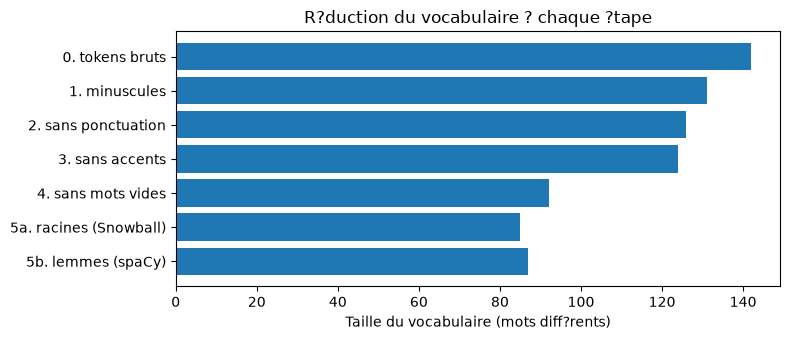

In [42]:
plt.figure(figsize=(8, 3.5))
plt.barh(resultats["?tape"], resultats["vocabulaire"])
plt.gca().invert_yaxis()
plt.xlabel("Taille du vocabulaire (mots diff?rents)")
plt.title("R?duction du vocabulaire ? chaque ?tape")
plt.tight_layout()
plt.show()

### Exercice 4.4 : la fonction finale `normaliser_tp3()`
Assemblez **votre** chaîne de traitement dans une fonction réutilisable (TP6, TP8) :
`preprocess` → spaCy → retrait de la ponctuation et des mots vides adaptés → **lemmes** (par défaut) ou **racines**.

In [43]:
def normaliser_tp3(texte, methode="lemmes"):
    doc = nlp_fr(preprocess(texte))
    if methode == "lemmes":
        return [t.lemma_.lower() for t in doc if garde(t)]
    elif methode == "racines":
        return [stemmer_fr.stem(t.lower_) for t in doc if garde(t)]
    raise ValueError("methode doit ?tre 'lemmes' ou 'racines'")

for texte, etiquette in AVIS[:3] + AVIS[-2:]:
    print(etiquette, normaliser_tp3(texte))

pos ['tajine', 'délicieux', 'service', 'très', 'rapide', 'recommander']
neg ['service', 'très', 'lent', 'arriver', 'froid', 'ne', 'recommander', 'pas']
pos ['serveur', 'aimable', 'cadre', 'magnifique', '😍']
pos ['bon']
neg ['ne', 'pas', 'bon']


In [44]:
# ✅ Test 4.4
assert normaliser_tp3("Les serveurs étaient aimables !") == ["serveur", "aimable"], "méthode lemmes : garde(t) et t.lemma_.lower()"
assert normaliser_tp3("Les serveurs étaient aimables !", "racines") == ["serveur", "aimabl"], "méthode racines : stemmer_fr.stem(t.lower_)"
assert normaliser_tp3("Le plat est bon.") != normaliser_tp3("Le plat n'est pas bon."), "la négation doit être conservée"
print("✅ Exercice 4.4 réussi : normaliser_tp3() est prête pour les TP suivants")

✅ Exercice 4.4 réussi : normaliser_tp3() est prête pour les TP suivants


### ?? Conclusion (livrable)
R?digez un **commentaire de 6 ? 10 lignes** du tableau de l'exercice 4.2 en r?pondant ? ces questions :
1. Quelle ?tape r?duit le **plus** le vocabulaire ? Et le nombre de tokens ?
2. Racines ou lemmes : lequel r?duit le plus le vocabulaire ? Pourquoi ?
3. Quelles informations a-t-on **perdues** en route (citez des exemples du corpus) ?
4. Pour l'**analyse de sentiment** du TP8, quelle cha?ne de traitement choisissez-vous ? Justifiez.

> **Votre commentaire (6 ? 10 lignes) :**
> La suppression des mots vides adapt?s r?duit le plus fortement le nombre de tokens, car elle retire les mots grammaticaux fr?quents.
> Le vocabulaire diminue aussi ? cette ?tape ; la normalisation par racines le r?duit g?n?ralement davantage que les lemmes en fusionnant davantage de variantes.
> La casse et les accents disparaissent lors des premi?res normalisations, et la ponctuation est supprim?e.
> La racinisation peut tronquer les mots (par exemple `aimable` devient `aimabl`) et fusionner des termes de sens diff?rents.
> La lemmatisation conserve des formes lexicales interpr?tables, mais un mod?le peut se tromper sur un mot rare ou mal ?crit.
> Supprimer `pas` ou `n'` ferait perdre la n?gation, comme dans ? le plat n'est pas bon ?.
> Pour l'analyse de sentiment du TP8, je choisirais `preprocess`, le retrait des mots vides adapt? en conservant n?gation et intensit?, puis la lemmatisation.
> Cette cha?ne limite les variantes tout en gardant les indices essentiels de polarit? et des r?sultats compr?hensibles.

## Pour aller plus loin (étudiants rapides)
### A. Un correcteur orthographique sur le corpus
Le corpus contient des fautes de frappe (« restaurent », « magnifque »). Utilisez la distance de Levenshtein du
cours pour proposer une correction : un mot **rare** (vu une seule fois) est remplacé par le mot **fréquent**
le plus proche, s'il est à une distance de 1 ou 2.

In [45]:
from nltk.metrics.distance import edit_distance     # distance de Levenshtein (cours, partie 3)

freq_mots = Counter(m for d in docs for m in (t.lower_ for t in d if t.is_alpha))
connus = {m: f for m, f in freq_mots.items() if f >= 2}  # mots vus au moins 2 fois
print(len(connus), "mots connus, ex. :", sorted(connus)[:8])

36 mots connus, ex. : ['accueil', 'bon', 'cadre', 'chaud', 'commande', 'de', 'en', 'est']


In [46]:
def corriger(mot, max_dist=2):
    if mot in connus:
        return mot
    candidats = [
        (edit_distance(mot, candidat), -frequence, candidat)
        for candidat, frequence in connus.items()
    ]
    if not candidats:
        return mot
    distance, _, meilleur = min(candidats)
    return meilleur if distance <= max_dist else mot

for m in ["restaurent", "magnifque", "servise", "tajine", "excellentes"]:
    print(f"{m:12} -> {corriger(m)}")

restaurent   -> restaurant
magnifque    -> magnifque
servise      -> service
tajine       -> tajine
excellentes  -> excellentes


?? ? magnifque ? est-il corrig? ? Pourquoi ? Que faudrait-il pour mieux corriger ?

> **Votre r?ponse :**
> Non, `magnifque` reste inchang? : le candidat bien orthographi? `magnifique` n'est vu qu'une seule fois et n'appartient donc pas ? `connus` (mots vus au moins deux fois). Il faudrait enrichir le lexique, par exemple avec un dictionnaire fran?ais, ou utiliser le contexte et un mod?le de correction orthographique.

### B. NLTK contre spaCy dans la chaîne
Refaites l'étape « 4. sans mots vides » avec la liste **NLTK** au lieu de votre liste adaptée. Comparez la taille du
vocabulaire et vérifiez si `n'` et `pas` sont conservés. Expliquez la différence.

In [47]:
etape4_nltk = [
    [t.lower_ for t in d if not t.is_punct and not t.is_space and t.lower_ not in sw_nltk]
    for d in docs
]
voc_nltk = {mot for liste in etape4_nltk for mot in liste}
print("Vocabulaire avec la liste NLTK :", len(voc_nltk), "| avec la liste adapt?e :",
      taille_vocabulaire(etapes["4. sans mots vides"]))
print("n' gard? :", "n'" in voc_nltk, "| pas gard? :", "pas" in voc_nltk)

Vocabulaire avec la liste NLTK : 100 | avec la liste adapt?e : 92
n' gard? : True | pas gard? : False


?? **Votre explication :**

> NLTK retire `pas` car ce mot figure dans sa liste, alors que `n'` reste : le token spaCy inclut l'apostrophe, contrairement au `n` de NLTK. La liste adapt?e conserve explicitement les marqueurs de n?gation et d'intensit?, donc elle garde `n'` et `pas`. Les vocabulaires diff?rent aussi parce que les listes de mots vides ne couvrent pas les m?mes formes ; pour le sentiment, pr?server la n?gation est plus important que retirer quelques tokens suppl?mentaires.

### C. Le même tableau pour l'anglais
Construisez le tableau de la partie 4 pour le corpus `ENGLISH` (modèle `nlp_en`, liste `nlp_en.Defaults.stop_words`,
Porter ou Snowball anglais). Les réductions sont-elles du même ordre qu'en français ?

In [48]:
docs_en = list(nlp_en.pipe([t for t, _ in ENGLISH]))
sw_en = nlp_en.Defaults.stop_words - {"not", "no", "n't", "never", "very"}

porter_en = PorterStemmer()
etapes_en = {
    "0. tokens bruts": [[t.text for t in d] for d in docs_en],
    "1. minuscules": [[t.lower_ for t in d] for d in docs_en],
    "2. sans ponctuation": [[t.lower_ for t in d if not t.is_punct and not t.is_space] for d in docs_en],
    "3. sans accents": [[sans_accents(t.lower_) for t in d if not t.is_punct and not t.is_space] for d in docs_en],
    "4. sans mots vides": [[t.lower_ for t in d if not t.is_punct and not t.is_space and t.lower_ not in sw_en] for d in docs_en],
    "5a. racines (Porter)": [[porter_en.stem(t.lower_) for t in d if not t.is_punct and not t.is_space and t.lower_ not in sw_en] for d in docs_en],
    "5b. lemmes (spaCy)": [[t.lemma_.lower() for t in d if not t.is_punct and not t.is_space and t.lower_ not in sw_en] for d in docs_en],
}
v0_en = taille_vocabulaire(etapes_en["0. tokens bruts"])
resultats_en = pd.DataFrame([
    {"?tape": nom, "tokens": nb_tokens(l), "vocabulaire": taille_vocabulaire(l),
     "r?duction du vocabulaire": f"{1 - taille_vocabulaire(l) / v0_en:.0%}"}
    for nom, l in etapes_en.items()
])
resultats_en

,?tape,tokens,vocabulaire,r?duction du vocabulaire
0,0. tokens bruts,61,43,0%
1,1. minuscules,61,42,2%
2,2. sans ponctuation,53,39,9%
3,3. sans accents,53,39,9%
4,4. sans mots vides,31,31,28%
5,5a. racines (Porter),31,31,28%
6,5b. lemmes (spaCy),31,31,28%


?? **Votre explication :** les r?ductions sont-elles du m?me ordre qu'en fran?ais ? Pourquoi ?

> Les r?ductions suivent des tendances comparables : la suppression des mots vides retire les tokens grammaticaux, puis la racinisation ou la lemmatisation fusionne certaines formes. Les valeurs exactes ne sont pas directement comparables, car le corpus anglais est beaucoup plus petit (6 avis contre 26 en fran?ais) et contient d'autres formes grammaticales. Les outils linguistiques et leurs r?gles morphologiques diff?rent aussi selon la langue.

---
### Rendu
1. Vérifiez que **tous les tests** affichent ✅.
2. Vérifiez que les réponses ✍️ et la **conclusion** sont rédigées.
3. *Exécution* → *Redémarrer et tout exécuter*, puis enregistrez le notebook sous le nom affiché en partie 0.1.